## 1 — Imports and dataset loading

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline

DATA_PATH = Path("household_power_consumption.txt")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place {DATA_PATH.name} next to this notebook before running.")

df = pd.read_csv(DATA_PATH, sep=";", na_values=["?"], low_memory=False)
print("Raw shape:", df.shape)
display(df.head())

Raw shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 2 — Data cleaning and validation
Missing numeric values in the source dataset may be recorded as `?`; `read_csv` converts those to `NaN`. We check and remove completely incomplete measurement rows. The date/time columns are preserved as a single timestamp.

In [2]:
numeric_source_cols = [c for c in df.columns if c not in ["Date", "Time"]]
for col in numeric_source_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing by column:")
display(df.isna().sum().to_frame("Missing"))
print("Rows with any missing numeric readings:", df[numeric_source_cols].isna().any(axis=1).sum())

# Keep original df unchanged; only complete measurements continue to hourly analysis.
df_clean = df.dropna(subset=numeric_source_cols + ["Date", "Time"]).copy()
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Date"] + " " + df_clean["Time"],
    dayfirst=True, errors="raise"
)
df_clean = df_clean.drop(columns=["Date", "Time"]).sort_values("Datetime")
print("Clean shape:", df_clean.shape)
display(df_clean.head())

Missing by column:


,Missing
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


Rows with any missing numeric readings: 25979
Clean shape: (2049280, 8)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


## 3 — Exploratory analysis
Outliers are **not automatically removed**: peaks may reflect real appliance usage. In the first two sub-metering columns, many readings are zero, making the usual IQR rule less informative.

In [3]:
display(df_clean[numeric_source_cols].describe().T.round(3))
q1 = df_clean[numeric_source_cols].quantile(.25)
q3 = df_clean[numeric_source_cols].quantile(.75)
iqr = q3 - q1
outlier_flag = (df_clean[numeric_source_cols] < q1 - 1.5 * iqr) | (df_clean[numeric_source_cols] > q3 + 1.5 * iqr)
checks = pd.DataFrame({
    "IQR_outlier_pct": (outlier_flag.mean() * 100).round(2),
    "Zero_pct": (df_clean[numeric_source_cols].eq(0).mean() * 100).round(2)
})
display(checks)

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000


,IQR_outlier_pct,Zero_pct
Global_active_power,4.63,0.00
Global_reactive_power,1.97,23.50
Voltage,2.49,0.00
Global_intensity,4.93,0.00
Sub_metering_1,8.25,91.75
Sub_metering_2,3.76,70.11
Sub_metering_3,0.00,41.58


## 4 — Create hourly measurements
Each hour summarizes minute readings. `Avg_Power` (kW) is the hourly mean, `Max_Power` (kW) is the peak minute reading, and `Meter_1`–`Meter_3` are recorded energy (kWh) for device groups. We keep hours with at least 54 of 60 minute readings. **Energy totals from partly observed hours are undercounts**, not estimated full-hour consumption.

In [4]:
hourly = df_clean.set_index("Datetime").resample("h").agg({
    "Global_active_power": ["mean", "max", "sum", "count"],
    "Sub_metering_1": "sum",
    "Sub_metering_2": "sum",
    "Sub_metering_3": "sum"
})
hourly.columns = ["Avg_Power", "Max_Power", "Total_Power_Sum", "Readings_Count", "Meter_1", "Meter_2", "Meter_3"]
print("Hours before completeness filter:", len(hourly))
hourly = hourly[hourly["Readings_Count"] >= 54].copy()
# One-minute active-power readings (kW) converted to recorded hourly energy (kWh).
hourly["Total_Energy"] = hourly["Total_Power_Sum"] / 60
hourly[["Meter_1", "Meter_2", "Meter_3"]] /= 1000
hourly = hourly.drop(columns="Total_Power_Sum")
print("Hours kept:", len(hourly))
print("Partial hours (54–59 readings):", (hourly["Readings_Count"] < 60).sum())
display(hourly.head())

Hours before completeness filter: 34589
Hours kept: 34143
Partial hours (54–59 readings): 58


,Avg_Power,Max_Power,Readings_Count,Meter_1,Meter_2,Meter_3,Total_Energy
Datetime,,,,,,,
2006-12-16 18:00:00,3.632200,6.752,60,0.0,0.403,1.012,3.632200
2006-12-16 19:00:00,3.400233,4.070,60,0.0,0.086,1.001,3.400233
2006-12-16 20:00:00,3.268567,3.496,60,0.0,0.000,1.007,3.268567
2006-12-16 21:00:00,3.056467,3.502,60,0.0,0.025,1.033,3.056467
2006-12-16 22:00:00,2.200133,3.464,60,0.0,0.008,0.266,2.200133


## 5 — Features and preprocessing
We exclude `Total_Energy` because it is nearly redundant with `Avg_Power` over complete hours. `Readings_Count` is a quality indicator, not a clustering feature. Hour and timestamp are kept for visualization, not fed directly to K-Means.

In [5]:
FEATURES = ["Avg_Power", "Max_Power", "Meter_1", "Meter_2", "Meter_3"]
X = hourly[FEATURES].copy()
assert not X.isna().any().any()
print("Model feature matrix:", X.shape)
display(X.head())

Model feature matrix: (34143, 5)


,Avg_Power,Max_Power,Meter_1,Meter_2,Meter_3
Datetime,,,,,
2006-12-16 18:00:00,3.632200,6.752,0.0,0.403,1.012
2006-12-16 19:00:00,3.400233,4.070,0.0,0.086,1.001
2006-12-16 20:00:00,3.268567,3.496,0.0,0.000,1.007
2006-12-16 21:00:00,3.056467,3.502,0.0,0.025,1.033
2006-12-16 22:00:00,2.200133,3.464,0.0,0.008,0.266


## 6 — K-Means: choose cluster count
Inspect inertia (elbow) and silhouette across different K values. A good-looking score alone does not guarantee useful consumption categories. For speed, silhouette is evaluated on a fixed sample.

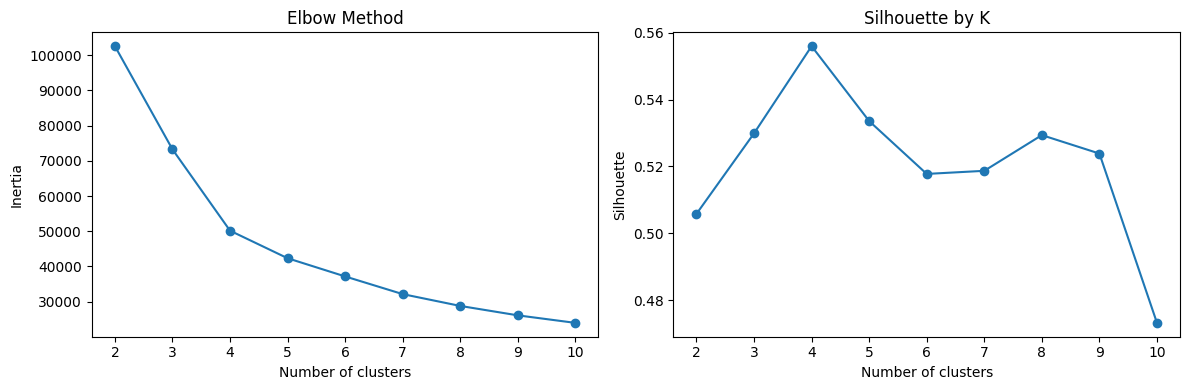

In [6]:
X_standard = StandardScaler().fit_transform(X)
ks = list(range(2, 11))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    y = km.fit_predict(X_standard)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_standard, y, sample_size=min(5000, len(X)), random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o")
ax[0].set(xlabel="Number of clusters", ylabel="Inertia", title="Elbow Method")
ax[1].plot(ks, silhouettes, marker="o")
ax[1].set(xlabel="Number of clusters", ylabel="Silhouette", title="Silhouette by K")
plt.tight_layout(); plt.show()

## 7 — K-Means preprocessing comparison (K = 3)
Compare no scaling, StandardScaler, and RobustScaler as experiments. Silhouette values across different scalings measure different distance spaces, so interpret their cluster profiles too.

In [7]:
variants = {
    "No Scaling": X.to_numpy(),
    "StandardScaler": StandardScaler().fit_transform(X),
    "RobustScaler": RobustScaler().fit_transform(X)
}
scaling_results = []
for name, arr in variants.items():
    predicted = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(arr)
    scaling_results.append({
        "Method": name,
        "Silhouette_sample": round(silhouette_score(arr, predicted, sample_size=min(5000, len(X)), random_state=42), 4),
        "Cluster_sizes": sorted(pd.Series(predicted).value_counts().tolist())
    })
display(pd.DataFrame(scaling_results))

,Method,Silhouette_sample,Cluster_sizes
0,No Scaling,0.5135,"[6341, 11377, 16425]"
1,StandardScaler,0.5299,"[1210, 12213, 20720]"
2,RobustScaler,0.8594,"[807, 1218, 32118]"


## 8 — DBSCAN experiment
DBSCAN detects dense groups and labels isolated points as -1 (noise). Noise is *not proof of an electrical fault*. We check multiple eps choices; DBSCAN was not selected as the primary consumption-level segmentation model.

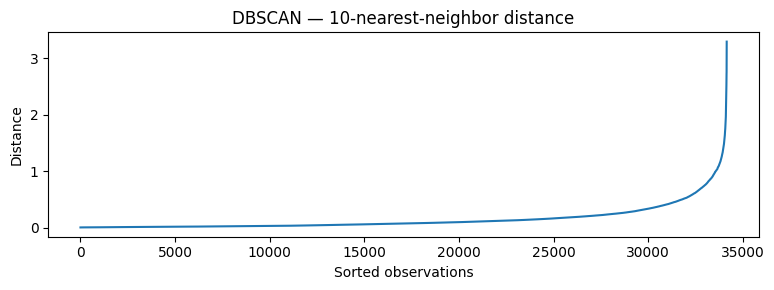

,eps,Clusters,Noise_hours,Noise_pct,Largest_cluster
0,0.3,16,3791,11.10,29181
1,0.5,4,1681,4.92,32402
2,0.7,5,885,2.59,33201


In [8]:
X_dbscan = X_standard
neighbor_count = 10
neighbor_dist = NearestNeighbors(n_neighbors=neighbor_count).fit(X_dbscan).kneighbors(X_dbscan)[0][:, -1]
plt.figure(figsize=(8, 3)); plt.plot(np.sort(neighbor_dist))
plt.title("DBSCAN — 10-nearest-neighbor distance"); plt.xlabel("Sorted observations"); plt.ylabel("Distance")
plt.tight_layout(); plt.show()

dbscan_rows = []
for eps in [0.3, 0.5, 0.7]:
    db_labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_dbscan)
    dbscan_rows.append({
        "eps": eps,
        "Clusters": len(set(db_labels) - {-1}),
        "Noise_hours": int((db_labels == -1).sum()),
        "Noise_pct": round(100 * (db_labels == -1).mean(), 2),
        "Largest_cluster": int(pd.Series(db_labels[db_labels != -1]).value_counts().max()) if (db_labels != -1).any() else 0
    })
display(pd.DataFrame(dbscan_rows))

## 9 — Fair comparison: K-Means vs hierarchical
Hierarchical clustering is expensive on 34k hours, so **both algorithms** are fitted and evaluated on exactly the same 5,000-hour random sample with the same features and scaling.

In [9]:
X_sample = X.sample(n=min(5000, len(X)), random_state=42)
X_scaled_sample = StandardScaler().fit_transform(X_sample)
comparisons = []
for name, candidate in {
    "K-Means": KMeans(n_clusters=3, random_state=42, n_init=10),
    "Hierarchical": AgglomerativeClustering(n_clusters=3, linkage="ward")
}.items():
    candidate_labels = candidate.fit_predict(X_scaled_sample)
    comparisons.append({
        "Model": name,
        "Silhouette": round(silhouette_score(X_scaled_sample, candidate_labels), 4),
        "Cluster_sizes": sorted(pd.Series(candidate_labels).value_counts().tolist())
    })
display(pd.DataFrame(comparisons))

,Model,Silhouette,Cluster_sizes
0,K-Means,0.5308,"[185, 1774, 3041]"
1,Hierarchical,0.4657,"[677, 1970, 2353]"


## 10 — Final selected model: StandardScaler + K-Means (K = 3)
The final model is refitted on all retained hourly records. Labels 0/1/2 are arbitrary IDs; descriptive names are assigned **after fitting** using mean power per cluster.

In [10]:
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(n_clusters=3, random_state=42, n_init=10))
])
final_labels = final_pipeline.fit_predict(X)
final_results = hourly.copy()
final_results["Cluster"] = final_labels
final_results["Hour"] = final_results.index.hour

# Label clusters by ascending mean consumption rather than assuming cluster numbers.
cluster_order = final_results.groupby("Cluster")["Avg_Power"].mean().sort_values().index.tolist()
cluster_name_map = dict(zip(cluster_order, ["Low", "Medium", "High"]))
final_results["Pattern"] = final_results["Cluster"].map(cluster_name_map)

summary = final_results.groupby(["Cluster", "Pattern"]).agg(
    Hours=("Avg_Power", "count"),
    Avg_Power=("Avg_Power", "mean"),
    Max_Power=("Max_Power", "mean"),
    Total_Energy=("Total_Energy", "sum"),
    Meter_1=("Meter_1", "sum"),
    Meter_2=("Meter_2", "sum"),
    Meter_3=("Meter_3", "sum")
)
display(summary.round(2))

,,Hours,Avg_Power,Max_Power,Total_Energy,Meter_1,Meter_2,Meter_3
Cluster,Pattern,,,,,,,
0,Low,20720,0.51,1.15,10667.53,161.71,552.82,2037.56
1,High,1210,3.02,5.50,3649.86,252.27,1523.87,767.28
2,Medium,12213,1.88,3.34,22948.20,1884.59,583.66,10423.87


## 11 — Final visualizations

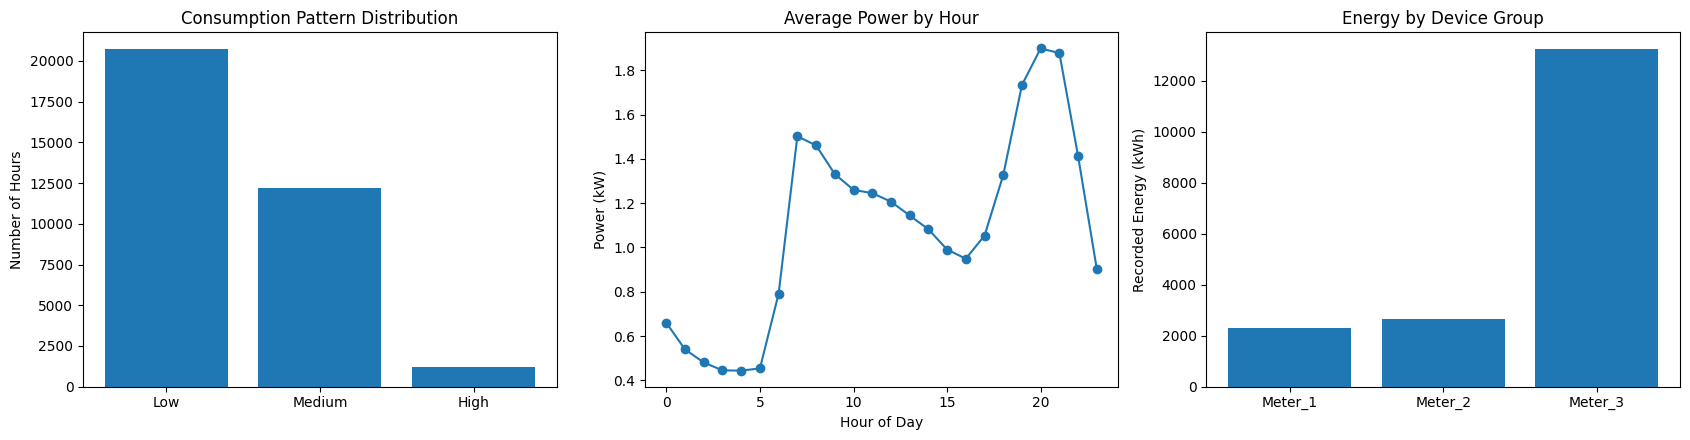

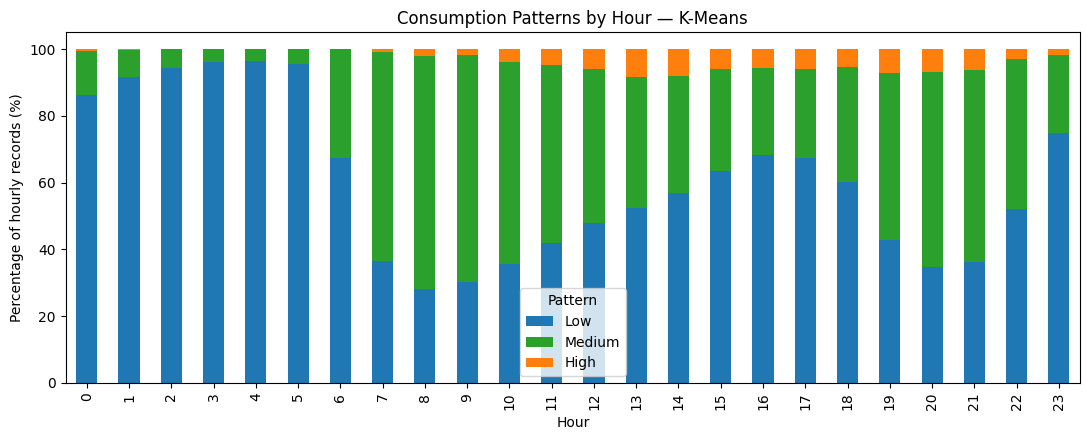

In [11]:
counts = final_results["Pattern"].value_counts().reindex(["Low", "Medium", "High"])
by_hour = final_results.groupby("Hour")["Avg_Power"].mean()
meters = final_results[["Meter_1", "Meter_2", "Meter_3"]].sum()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].bar(counts.index, counts.values)
axes[0].set(title="Consumption Pattern Distribution", ylabel="Number of Hours")
axes[1].plot(by_hour.index, by_hour.values, marker="o")
axes[1].set(title="Average Power by Hour", xlabel="Hour of Day", ylabel="Power (kW)")
axes[2].bar(meters.index, meters.values)
axes[2].set(title="Energy by Device Group", ylabel="Recorded Energy (kWh)")
plt.tight_layout(); plt.show()

pattern_hour = pd.crosstab(final_results["Hour"], final_results["Pattern"], normalize="index") * 100
pattern_hour = pattern_hour.reindex(columns=["Low", "Medium", "High"], fill_value=0)
pattern_hour.plot(kind="bar", stacked=True, figsize=(11, 4.5), color=["tab:blue", "tab:green", "tab:orange"])
plt.title("Consumption Patterns by Hour — K-Means")
plt.xlabel("Hour");plt.ylabel("Percentage of hourly records (%)")
plt.tight_layout();plt.show()

## 12 — Export artifacts for website integration
**Run only after fitting the final model.** Saves preprocessing + K-Means in one Pipeline to avoid inconsistent scaling, plus readable cluster names and a CSV for the dashboard. The future API should accept *hourly features in `FEATURES` order*. For minute-by-minute data, aggregate using the same rules as section 4 first.

In [12]:
OUTPUT_DIR = Path("website_artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final_pipeline, OUTPUT_DIR / "electricity_kmeans_pipeline.joblib")

metadata = {
    "features": FEATURES,
    "cluster_names": {str(k): v for k, v in cluster_name_map.items()},
    "frequency": "hourly",
    "min_readings_per_hour": 54,
    "units": {"Avg_Power": "kW", "Max_Power": "kW", "Meter_1": "kWh", "Meter_2": "kWh", "Meter_3": "kWh"},
    "note": "Historical household data. Meter 1-3 represent device groups, not individual appliances."
}
(OUTPUT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
final_results.to_csv(OUTPUT_DIR / "hourly_dashboard_data.csv", index_label="Datetime")
print("Saved:", [str(p) for p in OUTPUT_DIR.iterdir()])

Saved: ['website_artifacts/electricity_kmeans_pipeline.joblib', 'website_artifacts/model_metadata.json', 'website_artifacts/hourly_dashboard_data.csv']


## 13 — How to use the model in the website

```python
import joblib
import pandas as pd
import json

pipeline = joblib.load("website_artifacts/electricity_kmeans_pipeline.joblib")
meta = json.load(open("website_artifacts/model_metadata.json", encoding="utf-8"))

# Example hourly measurement; values are illustrations, NOT live sensor readings.
hour = pd.DataFrame([{
    "Avg_Power": 1.2, "Max_Power": 2.0,
    "Meter_1": 0.10, "Meter_2": 0.05, "Meter_3": 0.60
}])[meta["features"]]
cluster_id = int(pipeline.predict(hour)[0])
print(meta["cluster_names"][str(cluster_id)])
```

**Important:** `joblib` loads Python objects and must only be used with files you trust. Predictions are descriptive classifications, not forecasts. The website can separately rank device groups using sums of the three `Meter_*` columns. A single device within a group cannot be identified from this dataset.